# ĐỒ ÁN CUỐI KỲ: CSC17104 – LẬP TRÌNH CHO KHOA HỌC DỮ LIỆU
## PHẦN 3: BÀI TOÁN MACHINE LEARNING (Q6) – HỆ THỐNG CẢNH BÁO SỚM NĂM t+1
---
Tuân thủ 6 tiêu chuẩn khắt khe của Đề bài:
1. **User & No Leakage:** Người dùng rõ ràng, loại bỏ 100% cột năm t+1.
2. **Time-based split:** Train (1990–2010), Test (2011–2015).
3. **Pipeline & Models:** Trivial Baseline vs Ridge Regression vs Random Forest (toàn bộ tiền xử lý trong Pipeline).
4. **CV on Train only + Test once:** Cross-validation tinh chỉnh trên Train, Test 1 lần bằng MAE/RMSE.
5. **Error Analysis:** Phân tích sai số theo nhóm tuổi, giới tính, mức tỷ lệ.
6. **XAI & Answering:** Permutation Feature Importance và trả lời câu hỏi bằng số liệu chênh lệch MAE.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

sys.path.append(os.path.abspath('..'))
from src.visualization import set_academic_style
from src.utils import check_row_count

set_academic_style()
print("Scikit-learn và các công cụ Machine Learning đã sẵn sàng!")

Scikit-learn và các công cụ Machine Learning đã sẵn sàng!


### 3.3. Đặc tả câu hỏi Q6

**Câu hỏi:** Với số liệu có đến hết năm $t$, một hệ thống giám sát có thể dự báo tỷ lệ tự tử ở cấp nhóm (quốc gia × giới tính × nhóm tuổi) cho năm $t+1$ tốt hơn bao nhiêu so với cách đơn giản nhất là giữ nguyên tỷ lệ năm $t$?

- **Người dùng mục tiêu:** cơ quan y tế công cộng (bộ y tế, nhóm giám sát dịch tễ) cần tín hiệu sớm một năm để phân bổ nguồn lực phòng chống tự tử cho các nhóm dân số.
- **Quyết định được hỗ trợ:** nhóm nào có nguy cơ tăng trong năm tới để ưu tiên can thiệp; và mô hình có đáng dùng thay cho cách "giữ nguyên năm trước" hay không.
- **Biến đích:** `suicides/100k pop` của nhóm ở năm $t+1$. **Đơn vị mẫu:** một nhóm (country, sex, age) tại một năm $t$.

**Quy tắc chống rò rỉ dữ liệu (data leakage):**

1. Đặc trưng chỉ lấy từ năm $t$ và $t-1$. Mọi cột của năm $t+1$ (`suicides_no`, `population`, GDP, HDI) đều không được dùng.
2. Chia train/test **theo thời gian** của năm đích, không chia ngẫu nhiên.
3. Mọi bước tiền xử lý (impute, chuẩn hóa, one-hot) nằm **trong `Pipeline`**, chỉ được fit trên dữ liệu train của từng fold.
4. Chọn mô hình và siêu tham số **chỉ bằng cross-validation trên train**; tập test chỉ dùng **một lần** cho mô hình đã chốt.

**Không dùng:** `HDI for year` (train chỉ có 15.8% mẫu có HDI, test có 95.7%, xem mục 3.2.4), `generation` (suy ra hoàn toàn từ `year` và `age`), năm 2016 (chỉ 16 nước, thiếu nhóm 5-14).

### 3.4. Q6 – Tiền xử lý

**Bước 1:** đọc dữ liệu, đổi tên cột, loại năm 2016.

In [2]:
%matplotlib inline
from IPython.display import display
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from src.visualization import save_figure

raw = pd.read_csv(os.path.join('..', 'data', 'raw', 'master.csv'))
df = raw.rename(columns={'suicides/100k pop': 'rate',
                         'gdp_per_capita ($)': 'gdp_per_capita'})
df_before = df
df = df[df['year'] != 2016].copy()
check_row_count(df_before, df, "Q6 - Loại năm 2016")

[Q6 - Loại năm 2016]
  • Số dòng trước : 27,820
  • Số dòng sau   : 27,660
  • Thay đổi      : -160 dòng (-0.58%)



**Bước 2: dựng mẫu $(t-1, t, t+1)$.** Một mẫu cần nhóm đó có số liệu ở **cả ba năm liền nhau**. Chuỗi năm của nhiều nước bị đứt quãng (684 chỗ đứt ở 39 nước, mục 3.2.4), nên em không dùng `shift(1)`: `shift` lấy dòng liền trước trong bảng, có thể là năm cách xa. Thay vào đó, em ghép theo khóa `(country, sex, age, year)` với bảng đã dời năm ±1, nên chỉ ghép được khi năm liền kề thật sự tồn tại.

In [3]:
KEYS = ['country', 'sex', 'age']
cur = df[KEYS + ['year', 'rate', 'population', 'gdp_per_capita']]

# Tỷ lệ năm t-1: dời năm lên 1 để khớp với dòng năm t
prev = (cur[KEYS + ['year', 'rate']]
        .assign(year=lambda d: d['year'] + 1)
        .rename(columns={'rate': 'rate_prev'}))
# Biến đích: tỷ lệ năm t+1, dời năm xuống 1 để khớp với dòng năm t
nxt = (cur[KEYS + ['year', 'rate']]
       .assign(year=lambda d: d['year'] - 1)
       .rename(columns={'rate': 'target'}))

step = cur.merge(prev, on=KEYS + ['year'], how='inner',
                 validate='one_to_one')
check_row_count(cur, step, "Q6 - Giữ nhóm-năm có năm t-1 liền trước")
samples = step.merge(nxt, on=KEYS + ['year'], how='inner',
                     validate='one_to_one')
check_row_count(step, samples, "Q6 - Giữ nhóm-năm có năm t+1 liền sau")

samples = samples.rename(columns={'year': 'year_t', 'rate': 'rate_t',
                                  'population': 'population_t',
                                  'gdp_per_capita': 'gdp_per_capita_t'})
samples['target_year'] = samples['year_t'] + 1
samples_before = samples
samples = samples[samples['target_year'] >= 1990].reset_index(drop=True)
check_row_count(samples_before, samples, "Q6 - Giữ năm đích từ 1990")

# Đặc trưng phái sinh, đều tính từ năm t và t-1
samples['delta_rate'] = samples['rate_t'] - samples['rate_prev']
samples['log_population_t'] = np.log(samples['population_t'])
samples['log_gdp_per_capita_t'] = np.log(samples['gdp_per_capita_t'])

CAT_FEATURES = ['country', 'sex', 'age']
NUM_FEATURES = ['rate_t', 'rate_prev', 'delta_rate',
                'log_population_t', 'log_gdp_per_capita_t']
FEATURES = CAT_FEATURES + NUM_FEATURES
assert not any(c in FEATURES for c in ['target', 'target_year'])
print("Đặc trưng:", FEATURES)
samples[FEATURES + ['year_t', 'target_year', 'target']].head()

[Q6 - Giữ nhóm-năm có năm t-1 liền trước]
  • Số dòng trước : 27,660
  • Số dòng sau   : 25,776
  • Thay đổi      : -1,884 dòng (-6.81%)

[Q6 - Giữ nhóm-năm có năm t+1 liền sau]
  • Số dòng trước : 25,776
  • Số dòng sau   : 24,096
  • Thay đổi      : -1,680 dòng (-6.52%)

[Q6 - Giữ năm đích từ 1990]
  • Số dòng trước : 24,096
  • Số dòng sau   : 22,536
  • Thay đổi      : -1,560 dòng (-6.47%)

Đặc trưng: ['country', 'sex', 'age', 'rate_t', 'rate_prev', 'delta_rate', 'log_population_t', 'log_gdp_per_capita_t']


,country,sex,age,rate_t,rate_prev,delta_rate,log_population_t,log_gdp_per_capita_t,year_t,target_year,target
0,Albania,male,15-24 years,7.40,3.41,3.99,12.402051,6.079933,1993,1994,2.48
1,Albania,male,55-74 years,4.24,3.13,1.11,12.013701,6.079933,1993,1994,6.42
2,Albania,male,75+ years,4.13,0.00,4.13,10.094108,6.079933,1993,1994,8.13
3,Albania,male,25-34 years,3.91,2.85,1.06,12.346269,6.079933,1993,1994,2.59
4,Albania,female,15-24 years,3.51,2.39,1.12,12.561297,6.079933,1993,1994,2.12


**Bước 3: chia train/test theo năm đích.** Train gồm các mẫu có năm đích 1990–2010, test gồm năm đích 2011–2015. Mọi mẫu của cùng một năm đích nằm cùng một tập, và mô hình luôn được huấn luyện trên quá khứ để dự báo tương lai.

In [4]:
train = (samples[samples['target_year'] <= 2010]
         .sort_values(['target_year'] + KEYS).reset_index(drop=True))
test = samples[samples['target_year'] >= 2011].reset_index(drop=True)
X_train, y_train = train[FEATURES], train['target']
X_test, y_test = test[FEATURES], test['target']

split_table = pd.DataFrame({
    'Năm đích': ['1990–2010', '2011–2015'],
    'Số mẫu': [len(train), len(test)],
    'Số quốc gia': [train['country'].nunique(), test['country'].nunique()],
    'Tỷ lệ đích trung bình': [y_train.mean(), y_test.mean()],
}, index=['Train', 'Test'])
display(split_table.round(2))
only_test = sorted(set(test['country']) - set(train['country']))
print("Quốc gia chỉ có trong test:", only_test,
      "-> OneHotEncoder(handle_unknown='ignore')")
print(f"Tương quan giữa tỷ lệ năm t và năm t+1 trên train: "
      f"{train['rate_t'].corr(train['target']):.3f}")

,Năm đích,Số mẫu,Số quốc gia,Tỷ lệ đích trung bình
Train,1990–2010,18108,92,13.47
Test,2011–2015,4428,85,11.14


Quốc gia chỉ có trong test: ['Nicaragua', 'Turkey'] -> OneHotEncoder(handle_unknown='ignore')
Tương quan giữa tỷ lệ năm t và năm t+1 trên train: 0.930


### 3.4. Q6 – Mô hình

**Baseline (persistence):** $\hat{y}_{t+1} = y_t$, tức giữ nguyên tỷ lệ năm $t$. Tỷ lệ năm $t$ và $t+1$ tương quan rất mạnh, nên đây là baseline khó vượt hơn nhiều so với trung bình toàn cục.

**Cross-validation theo thời gian (chỉ trên train):** `TimeSeriesSplit(n_splits=5)` được áp dụng lên **danh sách 21 năm đích** của train, không áp dụng lên từng dòng, để một năm không bị cắt đôi giữa train và validation. Mỗi fold huấn luyện trên các năm trước và kiểm tra trên 3 năm ngay sau.

**Thước đo:** **MAE** là thước đo chính, vì cùng đơn vị với biến đích (ca/100.000 dân) và dễ diễn giải cho cơ quan y tế; tỷ lệ của các nhóm dân số nhỏ dao động mạnh, và RMSE sẽ phạt quá nặng các trường hợp này. **RMSE** được báo cáo kèm để thấy mức độ của các sai số lớn.

In [5]:
train_years = np.sort(train['target_year'].unique())
cv_folds, fold_rows = [], []
for k, (tr_y, va_y) in enumerate(
        TimeSeriesSplit(n_splits=5).split(train_years), start=1):
    tr_idx = np.flatnonzero(train['target_year'].isin(train_years[tr_y]))
    va_idx = np.flatnonzero(train['target_year'].isin(train_years[va_y]))
    cv_folds.append((tr_idx, va_idx))
    fold_rows.append({
        'Fold': k,
        'Năm đích train': f"{train_years[tr_y][0]}–{train_years[tr_y][-1]}",
        'Năm đích validation': f"{train_years[va_y][0]}–"
                               f"{train_years[va_y][-1]}",
        'Số mẫu train': len(tr_idx), 'Số mẫu validation': len(va_idx),
        'MAE persistence': mean_absolute_error(
            y_train.iloc[va_idx], X_train['rate_t'].iloc[va_idx]),
    })
fold_table = pd.DataFrame(fold_rows).set_index('Fold')
display(fold_table.round(3))
baseline_cv_mae = fold_table['MAE persistence'].mean()
print(f"MAE persistence trung bình 5 fold: {baseline_cv_mae:.3f}")

,Năm đích train,Năm đích validation,Số mẫu train,Số mẫu validation,MAE persistence
Fold,,,,,
1,1990–1995,1996–1998,3996,2544,2.780
2,1990–1998,1999–2001,6540,2808,3.036
3,1990–2001,2002–2004,9348,2964,2.850
4,1990–2004,2005–2007,12312,2856,3.205
5,1990–2007,2008–2010,15168,2940,2.461


MAE persistence trung bình 5 fold: 2.867


**Pipeline và hai cách đặt biến đích.** Mỗi mô hình là một `Pipeline`: `OneHotEncoder(handle_unknown='ignore')` cho `country`, `sex`, `age`; `SimpleImputer(median)` và `StandardScaler` cho các biến số. Có 2 mô hình theo kế hoạch:

- **Ridge Regression:** mô hình tuyến tính có điều chuẩn $L_2$.
- **Random Forest Regressor:** mô hình cây phi tuyến.

Mỗi mô hình được thử với **hai cách đặt biến đích**, đều để dự báo tỷ lệ năm $t+1$:

1. **Dự báo mức tỷ lệ:** mô hình học trực tiếp $y_{t+1}$.
2. **Dự báo mức thay đổi:** mô hình học $y_{t+1} - y_t$, rồi dự báo $\hat{y}_{t+1} = y_t + \widehat{(y_{t+1} - y_t)}$. Persistence chính là trường hợp mức thay đổi dự báo luôn bằng 0, nên mô hình chỉ phải học phần lệch so với baseline. Vì $y_{t+1} - \hat{y}_{t+1} = (y_{t+1} - y_t) - \widehat{(y_{t+1} - y_t)}$, MAE trên mức thay đổi **bằng đúng** MAE trên tỷ lệ, nên điểm CV của hai cách so sánh trực tiếp được.

Siêu tham số được chọn bằng `GridSearchCV` trên 5 fold ở trên, theo MAE. Cấu hình có MAE CV thấp nhất được chốt để đánh giá trên test.

In [6]:
def make_model_pipeline(model):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM_FEATURES),
    ])
    return Pipeline([('pre', pre), ('model', model)])


RIDGE_GRID = {'model__alpha': [0.1, 1, 10, 100, 1000, 10000, 100000]}
RF_GRID = {'model__max_depth': [10, None],
           'model__min_samples_leaf': [5, 20, 50],
           'model__max_features': [0.3, 0.5]}
CONFIGS = {
    'Ridge – dự báo mức tỷ lệ': (Ridge(), RIDGE_GRID, 'level'),
    'Ridge – dự báo mức thay đổi': (Ridge(), RIDGE_GRID, 'change'),
    'Random Forest – dự báo mức tỷ lệ': (
        RandomForestRegressor(n_estimators=200, random_state=42),
        RF_GRID, 'level'),
    'Random Forest – dự báo mức thay đổi': (
        RandomForestRegressor(n_estimators=200, random_state=42),
        RF_GRID, 'change'),
}
y_train_change = y_train - X_train['rate_t']

searches, cv_rows = {}, []
for name, (model, grid, target_kind) in CONFIGS.items():
    gs = GridSearchCV(make_model_pipeline(model), grid, cv=cv_folds,
                      scoring='neg_mean_absolute_error', n_jobs=-1)
    gs.fit(X_train, y_train if target_kind == 'level' else y_train_change)
    searches[name] = gs
    fold_mae = [-gs.cv_results_[f'split{k}_test_score'][gs.best_index_]
                for k in range(len(cv_folds))]
    cv_rows.append({
        'Cấu hình': name,
        'Siêu tham số tốt nhất': {k.replace('model__', ''): v
                                  for k, v in gs.best_params_.items()},
        'MAE CV': -gs.best_score_,
        'Độ lệch chuẩn giữa fold': np.std(fold_mae),
        'Số fold tốt hơn persistence': int(np.sum(
            np.array(fold_mae) < fold_table['MAE persistence'].to_numpy())),
    })

cv_table = pd.DataFrame(cv_rows).set_index('Cấu hình')
cv_table.loc['Persistence (baseline)'] = [
    '—', baseline_cv_mae, fold_table['MAE persistence'].std(ddof=0), '—']
cv_table['Cải thiện so với persistence (%)'] = (
    100 * (baseline_cv_mae - cv_table['MAE CV']) / baseline_cv_mae)
cv_table = cv_table.sort_values('MAE CV')
with pd.option_context('display.max_colwidth', None):
    display(cv_table.round(3))

best_name = cv_table.drop('Persistence (baseline)')['MAE CV'].idxmin()
best_model = searches[best_name].best_estimator_
best_kind = CONFIGS[best_name][2]
print("Cấu hình được chốt theo MAE CV:", best_name)

,Siêu tham số tốt nhất,MAE CV,Độ lệch chuẩn giữa fold,Số fold tốt hơn persistence,Cải thiện so với persistence (%)
Cấu hình,,,,,
Random Forest – dự báo mức thay đổi,"{'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 20}",2.712,0.192,5,5.408
Ridge – dự báo mức thay đổi,{'alpha': 10000},2.716,0.214,5,5.242
Random Forest – dự báo mức tỷ lệ,"{'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 5}",2.771,0.170,4,3.326
Ridge – dự báo mức tỷ lệ,{'alpha': 100},2.812,0.164,4,1.896
Persistence (baseline),—,2.867,0.251,—,0.000


Cấu hình được chốt theo MAE CV: Random Forest – dự báo mức thay đổi


### 3.4. Q6 – Đánh giá trên tập test (một lần duy nhất)

Mô hình đã chốt ở trên (đã được `GridSearchCV` fit lại trên toàn bộ train với siêu tham số tốt nhất) được đánh giá **một lần** trên test, cùng với baseline persistence.

In [7]:
def predict_rate(model, X, target_kind):
    # Đưa dự báo về đơn vị tỷ lệ năm t+1
    pred = model.predict(X)
    return X['rate_t'].to_numpy() + pred if target_kind == 'change' else pred


pred_base = X_test['rate_t'].to_numpy()
pred_model = predict_rate(best_model, X_test, best_kind)


def score_row(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}


test_table = pd.DataFrame({
    'Persistence (baseline)': score_row(y_test, pred_base),
    best_name: score_row(y_test, pred_model),
}).T
test_table.loc['Cải thiện (%)'] = (
    100 * (test_table.iloc[0] - test_table.iloc[1]) / test_table.iloc[0])
display(test_table.round(3))
print(f"Test: n = {len(test):,} mẫu, năm đích 2011–2015, "
      f"{test['country'].nunique()} quốc gia")
print("Số dự báo âm của mô hình:", int((pred_model < 0).sum()))

,MAE,RMSE
Persistence (baseline),2.213,5.844
Random Forest – dự báo mức thay đổi,2.065,4.848
Cải thiện (%),6.683,17.040


Test: n = 4,428 mẫu, năm đích 2011–2015, 85 quốc gia
Số dự báo âm của mô hình: 0


-> Đã lưu biểu đồ: ../data/processed/tv3_q6_fig1_actual_vs_pred.png


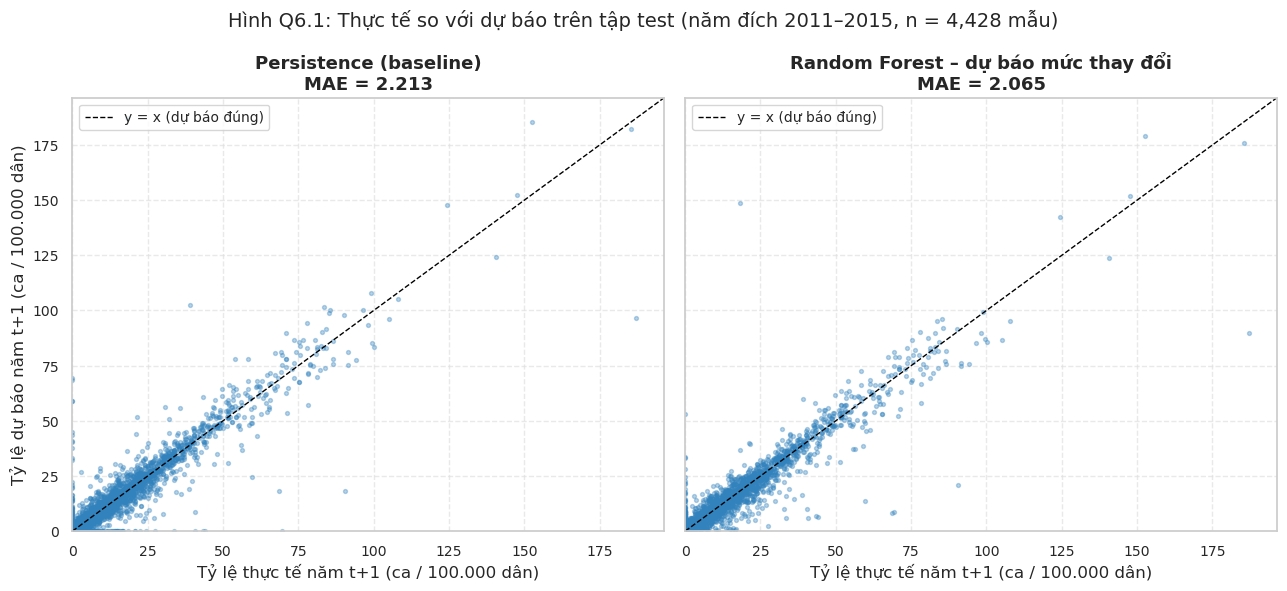

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
lim = max(y_test.max(), pred_model.max(), pred_base.max()) * 1.05
for ax, pred, title in [(axes[0], pred_base, 'Persistence (baseline)'),
                        (axes[1], pred_model, best_name)]:
    ax.scatter(y_test, pred, s=8, alpha=0.35, color='#3182bd')
    ax.plot([0, lim], [0, lim], color='black', linestyle='--',
            linewidth=1, label='y = x (dự báo đúng)')
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(f"{title}\nMAE = {mean_absolute_error(y_test, pred):.3f}")
    ax.set_xlabel('Tỷ lệ thực tế năm t+1 (ca / 100.000 dân)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Tỷ lệ dự báo năm t+1 (ca / 100.000 dân)')
fig.suptitle('Hình Q6.1: Thực tế so với dự báo trên tập test '
             f'(năm đích 2011–2015, n = {len(test):,} mẫu)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q6_fig1_actual_vs_pred.png')
plt.show()

### 3.4. Q6 – Phân tích lỗi

Em so MAE của baseline và mô hình trên từng nhóm: nhóm tuổi, giới tính, mức tỷ lệ nền của năm $t$ (thấp < 5, trung bình 5–30, cao > 30 ca/100.000 dân) và các nước chỉ xuất hiện trong test. Sau đó em liệt kê 5 mẫu có sai số lớn nhất của mô hình.

In [9]:
AGES = ['5-14 years', '15-24 years', '25-34 years', '35-54 years',
        '55-74 years', '75+ years']
err = test[KEYS + ['year_t', 'target_year', 'rate_prev', 'rate_t',
                   'target', 'population_t']].copy()
err['pred_base'] = pred_base
err['pred_model'] = pred_model
err['abs_err_base'] = (err['target'] - err['pred_base']).abs()
err['abs_err_model'] = (err['target'] - err['pred_model']).abs()
err['rate_level'] = pd.cut(err['rate_t'], bins=[-np.inf, 5, 30, np.inf],
                           labels=['Thấp (< 5)', 'Trung bình (5–30)',
                                   'Cao (> 30)'], right=False)
err['only_in_test'] = err['country'].isin(only_test)


def mae_by(col, order=None):
    t = err.groupby(col, observed=True).agg(
        n=('target', 'size'),
        mae_base=('abs_err_base', 'mean'),
        mae_model=('abs_err_model', 'mean'))
    t['cai_thien_pct'] = 100 * (t['mae_base'] - t['mae_model']) / t['mae_base']
    return t.loc[order] if order is not None else t


err_age = mae_by('age', AGES)
err_sex = mae_by('sex')
err_level = mae_by('rate_level')
for title, t in [('Theo nhóm tuổi', err_age), ('Theo giới tính', err_sex),
                 ('Theo mức tỷ lệ nền năm t', err_level),
                 ('Nước chỉ có trong test', mae_by('only_in_test'))]:
    print(title)
    display(t.round(3))

print("5 mẫu có sai số lớn nhất của mô hình:")
display(err.nlargest(5, 'abs_err_model')[
    KEYS + ['target_year', 'population_t', 'rate_prev', 'rate_t', 'target',
            'pred_base', 'pred_model', 'abs_err_model']].round(2))

Theo nhóm tuổi


,n,mae_base,mae_model,cai_thien_pct
age,,,,
5-14 years,738,0.434,0.504,-16.123
15-24 years,738,2.001,1.851,7.486
25-34 years,738,2.241,1.957,12.700
35-54 years,738,1.857,1.698,8.604
55-74 years,738,2.290,2.127,7.113
75+ years,738,4.454,4.254,4.493


Theo giới tính


,n,mae_base,mae_model,cai_thien_pct
sex,,,,
female,2214,1.238,1.152,6.952
male,2214,3.188,2.978,6.579


Theo mức tỷ lệ nền năm t


,n,mae_base,mae_model,cai_thien_pct
rate_level,,,,
Thấp (< 5),2127,1.005,1.185,-17.905
Trung bình (5–30),1864,2.488,2.215,10.959
Cao (> 30),437,6.916,5.705,17.519


Nước chỉ có trong test


,n,mae_base,mae_model,cai_thien_pct
only_in_test,,,,
False,4320,2.242,2.096,6.530
True,108,1.044,0.837,19.824


5 mẫu có sai số lớn nhất của mô hình:


,country,sex,age,target_year,population_t,rate_prev,rate_t,target,pred_base,pred_model,abs_err_model
3876,Suriname,male,75+ years,2013,5346,96.45,187.06,18.28,187.06,148.51,130.23
3864,Suriname,male,75+ years,2012,5184,100.12,96.45,187.06,96.45,89.66,97.40
3894,Suriname,male,75+ years,2014,5470,187.06,18.28,90.43,18.28,20.80,69.63
3467,Saint Vincent and Grenadines,male,75+ years,2014,1399,0.00,0.00,69.44,0.00,8.63,60.81
3564,Seychelles,male,55-74 years,2013,5437,0.00,18.39,68.65,18.39,8.15,60.50


-> Đã lưu biểu đồ: ../data/processed/tv3_q6_fig2_error_breakdown.png


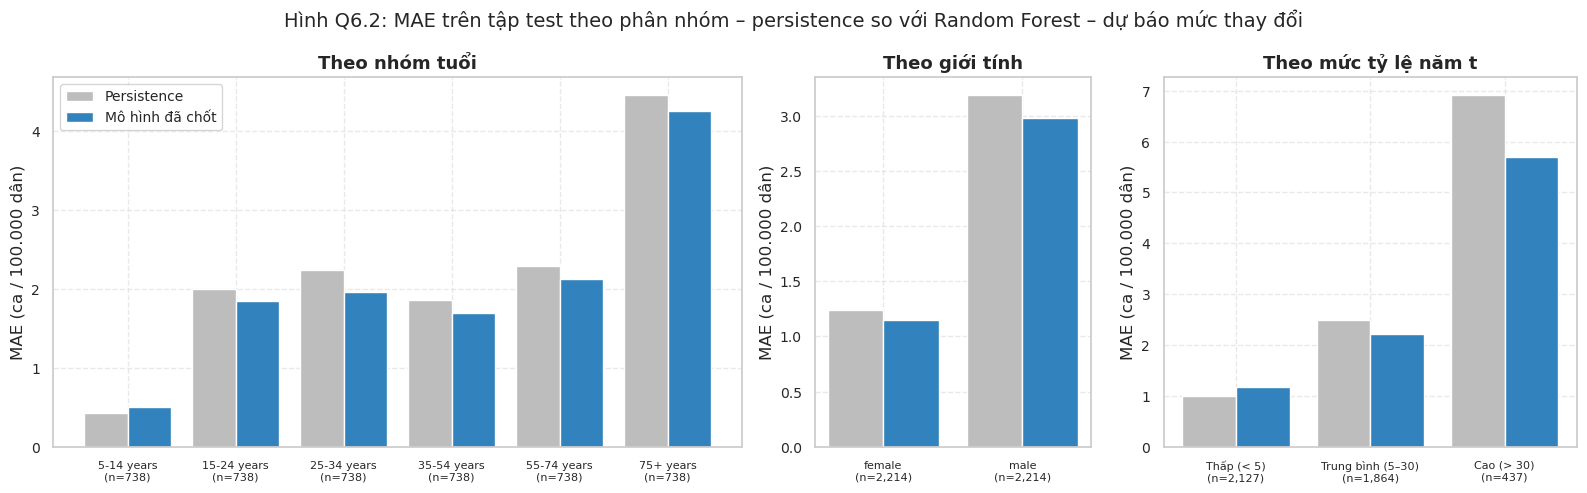

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5),
                         gridspec_kw={'width_ratios': [3, 1.2, 1.8]})
for ax, t, title in [(axes[0], err_age, 'Theo nhóm tuổi'),
                     (axes[1], err_sex, 'Theo giới tính'),
                     (axes[2], err_level, 'Theo mức tỷ lệ năm t')]:
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['mae_base'], width=0.4, color='#bdbdbd',
           label='Persistence')
    ax.bar(x + 0.2, t['mae_model'], width=0.4, color='#3182bd',
           label='Mô hình đã chốt')
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t['n'])],
                       fontsize=8)
    ax.set_title(title)
    ax.set_ylabel('MAE (ca / 100.000 dân)')
axes[0].legend(loc='upper left')
fig.suptitle('Hình Q6.2: MAE trên tập test theo phân nhóm – persistence so '
             f'với {best_name}')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q6_fig2_error_breakdown.png')
plt.show()

### 3.4. Q6 – Giải thích mô hình (Permutation Feature Importance)

Em xáo trộn ngẫu nhiên từng cột đặc trưng **gốc** trên tập test (10 lần mỗi cột) và đo MAE tăng thêm bao nhiêu. MAE tăng càng nhiều thì mô hình càng dựa vào cột đó. Hàm chấm điểm tính MAE trên **tỷ lệ năm $t+1$**. Với mô hình dự báo mức thay đổi, khi xáo cột `rate_t` thì cả phần $y_t$ cộng vào dự báo cũng bị xáo, nên độ quan trọng của `rate_t` gồm cả vai trò của persistence.

,MAE tăng thêm (trung bình),Độ lệch chuẩn
rate_t,11.1776,0.1050
delta_rate,0.4699,0.0072
log_population_t,0.1092,0.0107
rate_prev,0.0735,0.0072
age,0.0637,0.0023
sex,0.0555,0.0059
log_gdp_per_capita_t,0.0089,0.0012
country,0.0040,0.0034


-> Đã lưu biểu đồ: ../data/processed/tv3_q6_fig3_permutation_importance.png


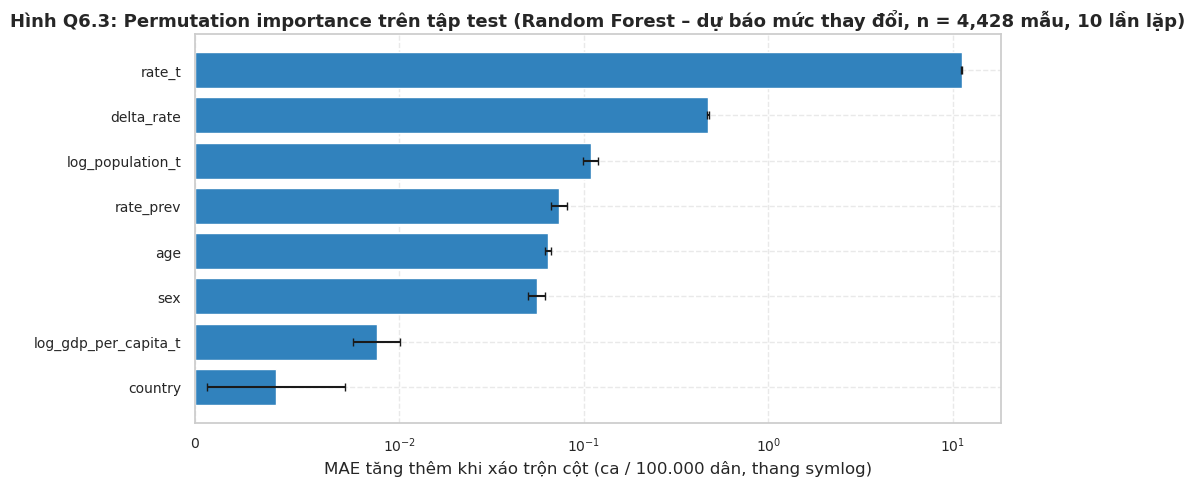

In [11]:
def neg_mae_rate(model, X, y):
    return -mean_absolute_error(y, predict_rate(model, X, best_kind))


perm = permutation_importance(best_model, X_test, y_test,
                              scoring=neg_mae_rate, n_repeats=10,
                              random_state=42, n_jobs=-1)
importance = pd.DataFrame({
    'MAE tăng thêm (trung bình)': perm.importances_mean,
    'Độ lệch chuẩn': perm.importances_std,
}, index=FEATURES).sort_values('MAE tăng thêm (trung bình)', ascending=False)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
imp = importance.iloc[::-1]
ax.barh(imp.index, imp['MAE tăng thêm (trung bình)'],
        xerr=imp['Độ lệch chuẩn'], color='#3182bd', capsize=3)
ax.set_xscale('symlog', linthresh=0.01)
ax.set_xlabel('MAE tăng thêm khi xáo trộn cột (ca / 100.000 dân, '
              'thang symlog)')
ax.set_title('Hình Q6.3: Permutation importance trên tập test '
             f'({best_name}, n = {len(test):,} mẫu, 10 lần lặp)')
fig.tight_layout()
save_figure(fig, '../data/processed/tv3_q6_fig3_permutation_importance.png')
plt.show()

### 3.4. Q6 – Kết quả và thảo luận

> ✍️ **[TV3 tự viết trước khi khóa bài 27/11]** Trả lời trực tiếp câu hỏi Q6 bằng số liệu ở các bảng và Hình Q6.1–Q6.3: mô hình đã chốt cải thiện MAE và RMSE bao nhiêu % so với persistence trên test, và có nhất quán với kết quả CV không; mô hình dự báo kém ở nhóm nào và vì sao (dựa vào 5 mẫu sai số lớn nhất); đặc trưng nào quan trọng nhất; mô hình có đủ tin cậy để triển khai không; giới hạn (GDP danh nghĩa, nhóm dân số nhỏ dao động mạnh, chỉ dự báo trước 1 năm).